In [3]:
import pandas as pd 
import numpy as np 
import random
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
import time
from wassersteinDL import wasserstein_DL
import warnings
import os
from config import *

outputdir = "./cost_matrix"
os.system(f"mkdir -p {outputdir}")

cosmic = pd.read_csv(COSMIC_FILE, sep="\t", index_col=0)
sbs96 = cosmic.index



## M1

Linear combination of difference in 5' position, 3' position and the main substitution. We weight them 1-2-1 and fix the weights. 
`M = 1 * differs(prime5) + 2 * differs(sub) + 1 * differs(prime3)`

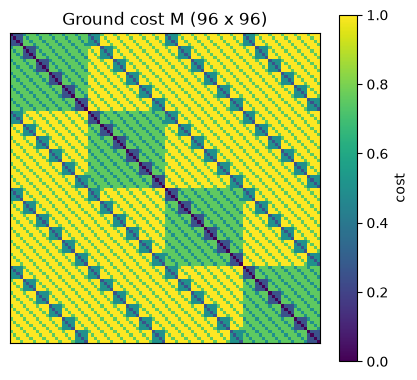

In [4]:
prime5  = sbs96.str[0].to_numpy()
sub   = sbs96.str[2:5].to_numpy()
prime3 = sbs96.str[-1].to_numpy()
differs = lambda x: (x[:, None] != x[None, :]).astype(float)

M = 1 * differs(prime5) + 2 * differs(sub) + 1 * differs(prime3)
M = M / M.max()
# M = pd.read_csv(REPO / "data/cost_matrix/C_graph_struct_scaled.csv", index_col=0).loc[sbs96, sbs96].to_numpy()

plt.figure(figsize=(5, 4.5))
plt.imshow(M, cmap="viridis"); plt.colorbar(label="cost")
plt.title("Ground cost M (96 x 96)"); plt.xticks([]); plt.yticks([])
plt.show()

# ***** save M for later use
pd.DataFrame(M, index=sbs96, columns=sbs96).to_csv(os.path.join(outputdir, "M1.csv"), float_format="%.10g")